In [1]:
from geometry_msgs.msg import Pose
import numpy as np

accepted_codes = ("G0", "G1", "G90", "G91")
rejected_actuations = ("E", "F")

def clean_gcode_line(l):
    split_actuations = l.split(" ")
    cleaned_actuations = list(filter(lambda l: not l.startswith(rejected_actuations), split_actuations))
    joined_actuations = " ".join(cleaned_actuations)
    return joined_actuations

def generate_waypoints(gcode_lines: list[str]):
    # Holds the presently parsed waypoint
    coords = {"x": 0.0, "y": 0.0, "z": 0.0}
    waypoints = []

    for line in gcode_lines:
        if "X" in line or "Y" in line or "Z" in line:
            for code in line.split(" "):
                match code[0]:
                    case "X":
                        coords["x"] = float(code[1:])/1000
                    case "Y":
                        coords["y"] = float(code[1:])/1000
                    case "Z":
                        coords["z"] = float(code[1:])/1000

            waypoints.append(np.array([
                coords["x"],
                coords["y"],
                coords["z"]
            ]))

    waypoints = np.array(waypoints)

    return waypoints    

In [ ]:
import plotly.express as px

def display_waypoints(waypoints):
    x = waypoints[:, 0]
    y = waypoints[:, 1]
    z = waypoints[:, 2]
    s = np.arange(len(waypoints))

    fig = px.scatter_3d(
        x=x,
        y=y,
        z=z,
        color=s,
        color_continuous_scale="Magma",
        labels={
            "x": "X Axis (m)",
            "y": "Y Axis (m)", 
            "z": "Z Axis (m)",
            "color": "Sequential order"},
        title="Interactive Plotly 3D Scatter Plot with 4D Intensity",
        opacity=0.8,
    )


    fig.update_traces(marker=dict(size=5))

    fig.show()

In [38]:
import matplotlib.pyplot as plt
import numpy as np


def display_waypoints_mp(waypoints):
    # Slice the waypoints array exactly like your Plotly version
    x = waypoints[:, 0]
    y = waypoints[:, 1]
    z = waypoints[:, 2]

    # Create the sequential order sequence for the colorbar mapping
    s = np.arange(len(waypoints))

    # 1. Initialize the layout figure size
    fig = plt.figure(figsize=(8, 5.5))

    # 2. Manually position the 3D canvas to maximize space on the left
    # Spans from x=0.0 to x=0.75, filling the left side tightly
    ax = fig.add_axes([0.0, 0.05, 0.72, 0.85], projection="3d")

    # 3. Scatter plot the points, matching your marker sizes and opacity (alpha)
    # Shaded by 's' (Sequential order) using the 'magma' colormap
    sc = ax.scatter(
        x, y, z, c=s, cmap="magma", s=25, alpha=0.8, depthshade=True
    )

    # 4. Set tight 3D bounding box ratios
    ax.set_box_aspect([1, 1, 0.4])

    # 5. Apply your exact custom labels and title
    ax.set_xlabel("X Axis (mm)")
    ax.set_ylabel("Y Axis (mm)")
    ax.set_zlabel("Z Axis (mm)")
    ax.set_title("3D bioprint waypoints")

    # 6. Place the colorbar tightly right beside the 3D plot box
    # Starts at x=0.75 (only a 3% gap away from the 3D plot window)
    cax = fig.add_axes([0.75, 0.2, 0.03, 0.55])
    cbar = fig.colorbar(sc, cax=cax)
    cbar.set_label("Sequential order")

    plt.show()

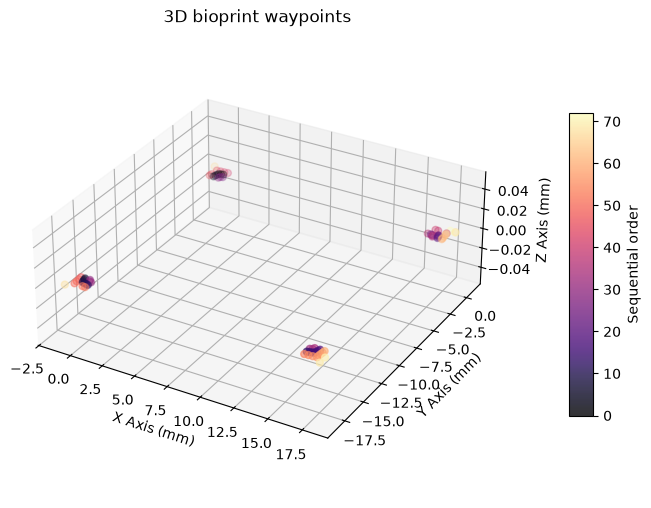

In [39]:
display_waypoints_mp(waypoints*1000)

In [3]:
print_name = "biosquare"

with open(f"../gcode/{print_name}.gcode", "r") as file:
    gcode_lines = file.readlines()

filtered_lines = list(filter(lambda l: l.startswith(accepted_codes), gcode_lines))
parsed_lines = list(map(lambda l: clean_gcode_line(l), filtered_lines))
waypoints = generate_waypoints(parsed_lines)[16:-2]

In [4]:
waypoints

array([[0.116617, 0.118795, 0.0002  ],
       [0.116456, 0.11875 , 0.0002  ],
       [0.116294, 0.118706, 0.0002  ],
       [0.11625 , 0.118544, 0.0002  ],
       [0.116205, 0.118383, 0.0002  ],
       [0.116161, 0.118221, 0.0002  ],
       [0.116161, 0.101779, 0.0002  ],
       [0.116205, 0.101617, 0.0002  ],
       [0.11625 , 0.101456, 0.0002  ],
       [0.116294, 0.101294, 0.0002  ],
       [0.116456, 0.10125 , 0.0002  ],
       [0.116617, 0.101205, 0.0002  ],
       [0.116779, 0.101161, 0.0002  ],
       [0.133221, 0.101161, 0.0002  ],
       [0.133383, 0.101205, 0.0002  ],
       [0.133544, 0.10125 , 0.0002  ],
       [0.133706, 0.101294, 0.0002  ],
       [0.13375 , 0.101456, 0.0002  ],
       [0.133795, 0.101617, 0.0002  ],
       [0.133839, 0.101779, 0.0002  ],
       [0.133839, 0.118221, 0.0002  ],
       [0.133795, 0.118383, 0.0002  ],
       [0.13375 , 0.118544, 0.0002  ],
       [0.133742, 0.118572, 0.0002  ],
       [0.133351, 0.118396, 0.0002  ],
       [0.133221, 0.11845

In [5]:
waypoints = waypoints - waypoints[0]

In [6]:
p1 = np.array([[60, 60, 0]])

# waypoints = waypoints + p1

In [12]:
display_waypoints(waypoints + p1/1000)

In [67]:
import yaml
import numpy as np

def read_pose_coordinates(pose_filename):
    with open(f"../poses/{pose_filename}.yaml", "r") as file:
        yaml_data = yaml.safe_load(file)

    coords = yaml_data["position"]
    position = np.array([coords['x'], coords['y'], coords['z']])
    return position

In [248]:
p1 = read_pose_coordinates("plane_p1")
p2 = read_pose_coordinates("plane_p2")
p3 = read_pose_coordinates("plane_p3")

u = p2 - p1
v = p3 - p1

n = np.cross(u, v)
a, b, c = n

d = np.dot(n, p1)

print(f"Plane equation: ({a})x + ({b})y + ({c})z = {d}")

Plane equation: (0.00019488394560094403)x + (0.00017991919553185293)y + (0.0024637924767927245)z = 0.0003073449940063747


In [243]:
x_p = u / np.linalg.norm(u)
z_p = n / np.linalg.norm(n)
y_p = np.cross(x_p, z_p) / np.linalg.norm(np.cross(x_p, z_p))

In [249]:
R = np.column_stack((x_p, y_p, z_p))
t = p1

In [264]:
transformed_points = np.apply_along_axis(lambda v: np.dot(R, v), axis=1, arr=waypoints)

In [265]:
display_waypoints(transformed_points)